# Laboratorio 10 — Redes Neuronales: de la Neurona al Entrenamiento
## Versión **docente**

**Curso:** Machine Learning (EIN143A25) · Paralelo 701
**Fecha:** Miércoles 11 de noviembre de 2026 · Clase 10 (día doble)
**Bloques:** 09:40-13:50 (día doble: teoría → lab → teoría → lab)

Este notebook reúne los dos laboratorios del día. Se trabaja en el mismo archivo y se entrega completo.

| Bloque | Parte | Tema | Tiempo sugerido |
|---|---|---|---|
| **Lab 1** (después de Teoría 1) | A | Perceptrón y XOR | 10 min |
| | B | Un MLP desde cero con NumPy | 25 min |
| | C | Dígitos con PyTorch | 25 min |
| | D | Preguntas de comprensión | 5 min |
| **Lab 2** (después de Teoría 2) | A | Optimizadores en comparación | 20 min |
| | B | Provocar sobreajuste | 10 min |
| | C | Remedios, uno por uno | 25 min |
| | D | Informe con incertidumbre | 10 min |

## Objetivos de aprendizaje

1. Describir una neurona, un perceptrón y un MLP, y calcular el número de parámetros de una red.
2. Explicar por qué se necesitan no linealidades y capas ocultas (problema XOR).
3. Aplicar la regla de la cadena para hacer *backpropagation* y comprobarla con diferencias finitas.
4. Explicar y comparar momentum, RMSprop y Adam.
5. Aplicar y justificar L2, Dropout, Batch Normalization y *early stopping* frente a un síntoma de entrenamiento.

> **Cómo se trabaja.** Las celdas con `# TODO` se completan; las celdas «Autocomprobación» fallan con un mensaje si algo no está bien implementado. Las preguntas se responden en la celda de texto que sigue a cada una.

> **Versión docente (con solución, ejecutada).** Entorno de validación: Python 3.13, CPU, sin GPU, `RAPIDO = False`. El conjunto de datos (`load_digits`) viene incluido en scikit-learn: no requiere descarga, por lo que **no se usó ningún reemplazo** de datos. Los números de las respuestas modelo salen de esta ejecución; con otra versión de librerías pueden variar levemente. Este archivo contiene las soluciones: mantenerlo fuera del repositorio de los estudiantes (`.gitignore`).

In [1]:
import sys, time, copy, warnings
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q numpy scikit-learn matplotlib pandas torch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score

SEED = 42
RAPIDO = False   # True: menos épocas, solo para probar el notebook rápido (valores del libreto = False)
np.random.seed(SEED); torch.manual_seed(SEED)
T0 = time.time()

EPOCAS = {"lab1": 30, "lr_corto": 15, "opt": 30, "sobreajuste": 200}
if RAPIDO:
    EPOCAS = {"lab1": 10, "lr_corto": 5, "opt": 10, "sobreajuste": 60}

MARINO, ROSA, GRIS = "#1b2740", "#c8807a", "#8b929c"
plt.rcParams.update({
    "figure.facecolor": "#f2f1ee", "axes.facecolor": "#fffefb", "axes.edgecolor": "#dcdad3",
    "axes.grid": True, "grid.color": "#e3e1da", "axes.prop_cycle": plt.cycler(color=[MARINO, ROSA, GRIS, "#9aa6b8", "#6c7480"]),
    "axes.titlesize": 13, "axes.labelsize": 11, "figure.dpi": 100,
})
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| RAPIDO =", RAPIDO)

Python 3.13.16 | numpy 2.5.3 | torch 2.14.1+cu130 | RAPIDO = False


---
# LAB 1 — Armar la red
---
## Parte A — Perceptrón y XOR (10 min)

El **perceptrón** (Rosenblatt, 1958) es una neurona con activación escalón: $\hat y = 1$ si $w\cdot x + b \ge 0$, si no $0$. Su regla de aprendizaje, ejemplo por ejemplo, es

$$w \leftarrow w + \eta\,(y - \hat y)\,x, \qquad b \leftarrow b + \eta\,(y - \hat y).$$

**Consigna.** Implementa `entrenar_perceptron` y entrénalo con las compuertas **AND** y **XOR**. Verifica que AND converge (cero errores por época) y que XOR no.

In [2]:
def graficar_frontera(predecir, X, y, titulo=""):
    """Dibuja la región de decisión de `predecir` (función que recibe una malla Nx2 y devuelve valores en [0, 1]) y los 4 puntos."""
    xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
    zz = np.asarray(predecir(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
    plt.contourf(xx, yy, zz, levels=[0, 0.5, 1], colors=["#c8d1de", "#e8cfcb"], alpha=0.8)
    plt.contour(xx, yy, zz, levels=[0.5], colors=[MARINO], linewidths=2)
    plt.scatter(X[:, 0], X[:, 1], c=np.where(np.ravel(y) == 1, ROSA, MARINO), s=140, edgecolor="white", zorder=3)
    plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title(titulo); plt.xlim(-0.5, 1.5); plt.ylim(-0.5, 1.5)


X_log = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_and = np.array([0, 0, 0, 1])
y_xor = np.array([0, 1, 1, 0])


def escalon(z):
    return np.where(z >= 0, 1, 0)

In [3]:
def entrenar_perceptron(X, y, eta=0.1, epocas=50, seed=SEED):
    """Regla del perceptrón. Devuelve (w, b, errores_por_epoca)."""
    rng = np.random.default_rng(seed)
    w = rng.normal(0, 0.1, size=X.shape[1])
    b = 0.0
    errores = []
    for _ in range(epocas):
        err = 0
        for xi, yi in zip(X, y):
            yhat = escalon(xi @ w + b)
            delta = eta * (yi - yhat)
            w = w + delta * xi
            b = b + delta
            err += int(yhat != yi)
        errores.append(err)
    return w, b, errores

AND: errores en la última época = 0 | XOR: errores en la última época = 4


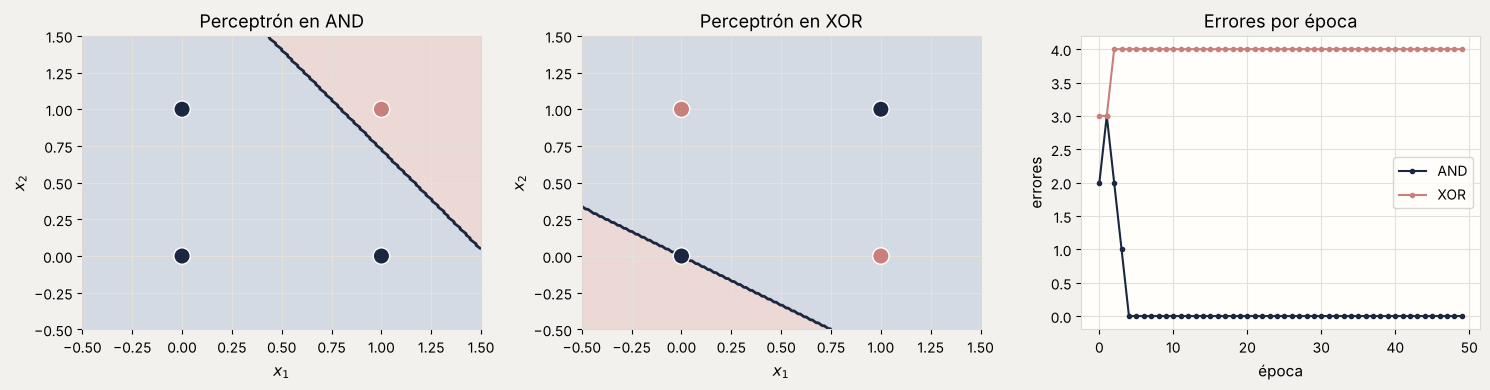

In [4]:
w_and, b_and, err_and = entrenar_perceptron(X_log, y_and)
w_xor, b_xor, err_xor = entrenar_perceptron(X_log, y_xor)

# Autocomprobación
assert len(err_and) == 50, "errores_por_epoca debe tener una entrada por época"
assert err_and[0] > 0, "La primera época de AND debería tener errores (el perceptrón parte con pesos aleatorios): ¿completaste el TODO de entrenar_perceptron?"
assert err_and[-1] == 0, "AND es linealmente separable: el perceptrón debería terminar con 0 errores"
assert err_xor[-1] > 0, "XOR no es linealmente separable: no puede terminar con 0 errores"
print("AND: errores en la última época =", err_and[-1], "| XOR: errores en la última época =", err_xor[-1])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
plt.sca(ax[0]); graficar_frontera(lambda M: escalon(M @ w_and + b_and).astype(float), X_log, y_and, "Perceptrón en AND")
plt.sca(ax[1]); graficar_frontera(lambda M: escalon(M @ w_xor + b_xor).astype(float), X_log, y_xor, "Perceptrón en XOR")
ax[2].plot(err_and, label="AND", marker="o", ms=3); ax[2].plot(err_xor, label="XOR", marker="o", ms=3)
ax[2].set_xlabel("época"); ax[2].set_ylabel("errores"); ax[2].set_title("Errores por época"); ax[2].legend()
plt.tight_layout(); plt.show()

**Pregunta:** ¿Por qué el perceptrón nunca llega a cero errores en XOR? Dibuja (o describe) los cuatro puntos y explica qué tendría que hacer una sola recta.

**Respuesta (modelo):** Los puntos (0,0) y (1,1) son de clase 0 y (0,1) y (1,0) de clase 1: las dos clases están en esquinas opuestas de un cuadrado. Una sola recta (que es lo que dibuja $w\\cdot x+b=0$) no puede dejar los dos puntos rosa de un lado y los dos azul del otro; siempre deja al menos un punto mal clasificado. Por eso en la última época el perceptrón sigue cometiendo errores (4 en esta ejecución, porque los pesos oscilan), mientras que en AND, que sí es linealmente separable, llega a 0 errores.

## Parte B — Un MLP desde cero con NumPy (25 min)

Red **2-4-1** para XOR: capa oculta de 4 neuronas con **tanh**, salida con **sigmoide**, pérdida **entropía cruzada binaria** (media sobre los $n$ ejemplos), gradiente descendente de lote completo con $\eta = 0{,}5$.

**Hacia adelante**

$$z_1 = XW_1 + b_1,\quad a_1 = \tanh(z_1),\quad z_2 = a_1W_2 + b_2,\quad \hat y = a_2 = \sigma(z_2).$$

**Hacia atrás** (regla de la cadena, con $n$ = número de ejemplos). Para sigmoide + entropía cruzada la derivada se simplifica:

$$\delta_2 = \frac{\hat y - y}{n},\quad \frac{\partial L}{\partial W_2} = a_1^\top\delta_2,\quad \frac{\partial L}{\partial b_2} = \sum \delta_2,\quad \delta_1 = (\delta_2 W_2^\top)\odot(1-a_1^2),\quad \frac{\partial L}{\partial W_1} = X^\top\delta_1,\quad \frac{\partial L}{\partial b_1} = \sum\delta_1.$$

**Consigna.**
1. Completa `forward`, `perdida`, `backward` y `paso`.
2. **Verifica tus gradientes** con diferencias finitas: $\dfrac{L(w+\varepsilon)-L(w-\varepsilon)}{2\varepsilon}$. El error relativo máximo debe ser menor que $10^{-6}$.
3. Entrena (`entrenar_xor`), grafica la curva de pérdida y la frontera de decisión aprendida.

In [5]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


def init_params(n_in=2, n_oc=4, n_out=1, seed=SEED):
    rng = np.random.default_rng(seed)
    return {"W1": rng.normal(0, 1, (n_in, n_oc)), "b1": np.zeros((1, n_oc)),
            "W2": rng.normal(0, 1, (n_oc, n_out)), "b2": np.zeros((1, n_out))}


y_col = y_xor.reshape(-1, 1).astype(float)   # las etiquetas como columna (n, 1)

In [6]:
def forward(p, X):
    """Paso hacia adelante. Devuelve (yhat, cache) con las activaciones que necesita backward."""
    z1 = X @ p["W1"] + p["b1"]
    a1 = np.tanh(z1)
    z2 = a1 @ p["W2"] + p["b2"]
    a2 = sigmoide(z2)
    return a2, {"X": X, "z1": z1, "a1": a1, "z2": z2, "a2": a2}


def perdida(y, yhat, eps=1e-12):
    """Entropía cruzada binaria media."""
    yhat = np.clip(yhat, eps, 1 - eps)
    return -np.mean(y * np.log(yhat) + (1 - y) * np.log(1 - yhat))


def backward(p, cache, y):
    """Gradientes de la pérdida respecto de W1, b1, W2, b2 (mismo formato que `p`)."""
    n = y.shape[0]
    dz2 = (cache["a2"] - y) / n
    dW2 = cache["a1"].T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    dz1 = (dz2 @ p["W2"].T) * (1 - cache["a1"] ** 2)
    dW1 = cache["X"].T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}


def paso(p, grads, eta):
    """Un paso de gradiente descendente (modifica `p` en el lugar)."""
    for k in p:
        p[k] -= eta * grads[k]

In [7]:
def verificar_gradientes(p, X, y, eps=1e-5):
    """Compara backward() con diferencias finitas centradas. Devuelve el error relativo máximo."""
    yhat, cache = forward(p, X)
    grads = backward(p, cache, y)
    assert grads is not None, "backward() todavía no devuelve los gradientes (revisa los TODO)."
    peor = 0.0
    for k in p:
        for idx in np.ndindex(*p[k].shape):
            original = p[k][idx]
            p[k][idx] = original + eps; lp = perdida(y, forward(p, X)[0])
            p[k][idx] = original - eps; lm = perdida(y, forward(p, X)[0])
            p[k][idx] = original
            g_num = (lp - lm) / (2 * eps)
            g_an = grads[k][idx]
            peor = max(peor, abs(g_num - g_an) / max(abs(g_num) + abs(g_an), 1e-12))
    return peor


# Autocomprobación de gradientes (con pesos aleatorios, antes de entrenar)
p_test = init_params()
yhat0, _ = forward(p_test, X_log)
assert yhat0.shape == (4, 1), "forward debe devolver un vector columna (n, 1)"
err_rel = verificar_gradientes(p_test, X_log, y_col)
print(f"Error relativo máximo entre backward() y diferencias finitas: {err_rel:.2e}")
assert err_rel < 1e-6, "Los gradientes no coinciden con las diferencias finitas: revisa backward()"
print("Gradientes correctos.")

Error relativo máximo entre backward() y diferencias finitas: 1.23e-08
Gradientes correctos.


In [8]:
def entrenar_xor(eta=0.5, iteraciones=2000, seed=SEED):
    """Entrena la red 2-4-1 en XOR. Devuelve (parametros, historial_de_perdida)."""
    p = init_params(seed=seed)
    hist = []
    for _ in range(iteraciones):
        yhat, cache = forward(p, X_log)
        hist.append(perdida(y_col, yhat))
        grads = backward(p, cache, y_col)
        paso(p, grads, eta)
    return p, hist

Pérdida final: 0.00239 | predicciones: [0 1 1 0] | objetivo: [0 1 1 0]


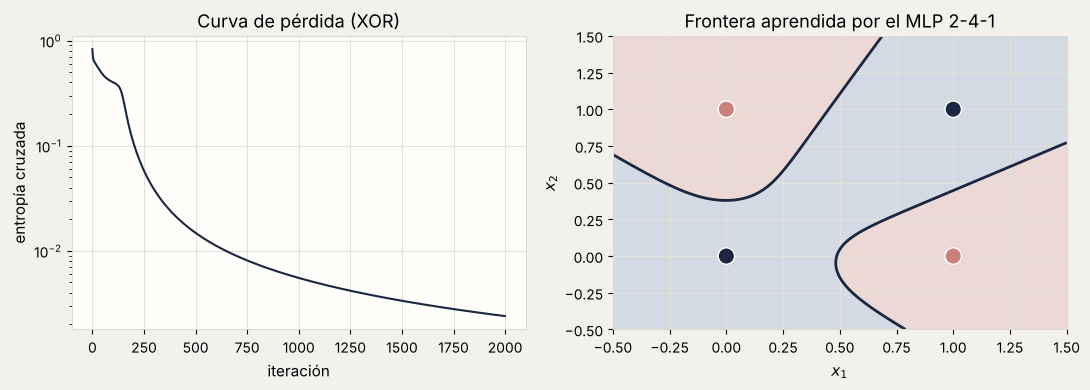

In [9]:
p_xor, hist_xor = entrenar_xor()
pred_xor = (forward(p_xor, X_log)[0] > 0.5).astype(int)

# Autocomprobación
assert hist_xor[-1] < 0.05, f"La pérdida final ({hist_xor[-1]:.3f}) debería ser < 0.05"
assert (pred_xor.ravel() == y_xor).all(), "La red debería clasificar bien los 4 puntos de XOR"
print(f"Pérdida final: {hist_xor[-1]:.5f} | predicciones: {pred_xor.ravel()} | objetivo: {y_xor}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_xor); ax[0].set_yscale("log"); ax[0].set_xlabel("iteración"); ax[0].set_ylabel("entropía cruzada"); ax[0].set_title("Curva de pérdida (XOR)")
plt.sca(ax[1]); graficar_frontera(lambda M: forward(p_xor, M)[0], X_log, y_xor, "Frontera aprendida por el MLP 2-4-1")
plt.tight_layout(); plt.show()

**Pregunta:** Mira la frontera: ¿qué tienen de distinto las capas ocultas respecto del perceptrón de la Parte A? Si cambias `seed` por 0 en `entrenar_xor`, ¿qué observas en la pérdida y por qué importa la inicialización?

**Respuesta (modelo):** Las neuronas ocultas con tanh transforman el espacio: cada una dibuja su propia recta y la capa de salida combina esas rectas, de modo que la frontera final es curva y puede aislar (0,1) y (1,0) de (0,0) y (1,1). El perceptrón tiene una sola recta. Con `seed=0` la pérdida se estanca en ≈ 0,35 y la red clasifica mal dos de los cuatro puntos (predice [0, 0, 1, 1]): la inicialización cae en una región plana (meseta) y el gradiente descendente no sale de ahí con 2.000 iteraciones. Con semillas 1, 2, 3 o 42 converge a ≈ 0,002. Moraleja: el resultado depende de la inicialización, por eso se fijan semillas y se repite con varias (idea que se retoma en la Parte D del Lab 2).

## Parte C — Dígitos con PyTorch (25 min)

Conjunto `load_digits` (1.797 imágenes de 8×8 píxeles, 10 clases), incluido en scikit-learn. Se escala a $[0,1]$ y se separa en entrenamiento/prueba (75 %/25 %, estratificado).

**Consigna.**
1. Define la red `64 → 64 → 32 → 10` con ReLU (`nn.Sequential`) en `crear_red_base()` y comprueba que tiene **6.570 parámetros**.
2. Escribe el ciclo de una época (`entrenar_una_epoca`): *forward → pérdida → `backward()` → `step()`*, recorriendo mini-batches de 64 con `DataLoader`.
3. Entrena con `nn.CrossEntropyLoss` y `SGD(lr=0.1)`, registra pérdida y exactitud por época, y reporta **matriz de confusión** y **F1 macro** (clase 9).

entrenamiento: torch.Size([1347, 64]) | prueba: torch.Size([450, 64])


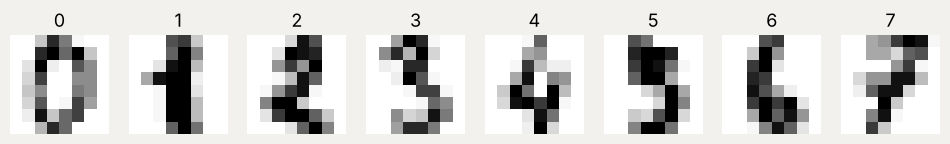

In [10]:
digits = load_digits()
X_all, y_all = digits.data / 16.0, digits.target
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.25, stratify=y_all, random_state=SEED)

def a_tensores(X, y):
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

Xtr_t, ytr_t = a_tensores(X_tr, y_tr)
Xte_t, yte_t = a_tensores(X_te, y_te)
print("entrenamiento:", Xtr_t.shape, "| prueba:", Xte_t.shape)

fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for a, img, lab in zip(ax, digits.images[:8], digits.target[:8]):
    a.imshow(img, cmap="Greys"); a.set_title(lab); a.axis("off")
plt.show()

In [11]:
def crear_red_base():
    """Red 64 -> 64 -> 32 -> 10 con ReLU."""
    return nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 10))

In [12]:
torch.manual_seed(SEED)
modelo = crear_red_base()
n_params = sum(p.numel() for p in modelo.parameters())
print("Parámetros:", n_params)
assert n_params == 6570, "La red 64-64-32-10 debe tener 64*64+64 + 64*32+32 + 32*10+10 = 6570 parámetros"
print(modelo)

Parámetros: 6570
Sequential(
  (0): Linear(in_features=64, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=10, bias=True)
)


In [13]:
def evaluar(modelo, X, y):
    """Pérdida, exactitud y predicciones del modelo en modo evaluación (sin gradientes)."""
    modelo.eval()
    with torch.no_grad():
        logits = modelo(X)
        perd = nn.functional.cross_entropy(logits, y).item()
        pred = logits.argmax(dim=1)
    return {"loss": perd, "acc": (pred == y).float().mean().item(), "pred": pred.numpy()}


def entrenar_una_epoca(modelo, optimizador, loader, criterio):
    """Una pasada por el DataLoader. Devuelve la pérdida media de la época."""
    modelo.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        optimizador.zero_grad()
        loss = criterio(modelo(xb), yb)
        loss.backward()
        optimizador.step()
        total += loss.item() * len(xb)
        n += len(xb)
    return total / n

Exactitud de prueba: 0.942 | pérdida de entrenamiento final: 0.1258


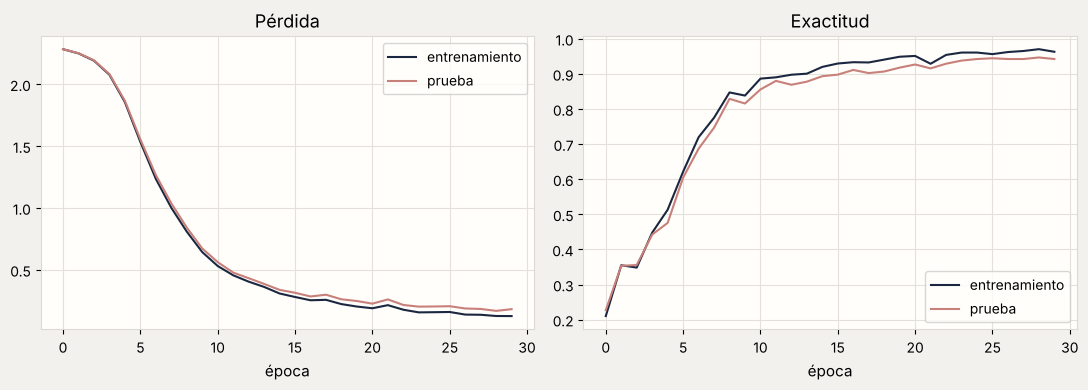

In [14]:
def entrenar(modelo, optimizador, X_tr, y_tr, X_ev, y_ev, epocas=30, batch_size=64, seed=SEED):
    """Entrena `epocas` épocas con mini-batches. Devuelve el historial por época:
    loss_tr, acc_tr (entrenamiento, en modo evaluación) y loss_ev, acc_ev (conjunto de evaluación)."""
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True, generator=g, drop_last=True)
    criterio = nn.CrossEntropyLoss()
    hist = {"loss_tr": [], "acc_tr": [], "loss_ev": [], "acc_ev": []}
    for _ in range(epocas):
        entrenar_una_epoca(modelo, optimizador, loader, criterio)
        r_tr, r_ev = evaluar(modelo, X_tr, y_tr), evaluar(modelo, X_ev, y_ev)
        hist["loss_tr"].append(r_tr["loss"]); hist["acc_tr"].append(r_tr["acc"])
        hist["loss_ev"].append(r_ev["loss"]); hist["acc_ev"].append(r_ev["acc"])
    return hist


torch.manual_seed(SEED)
modelo = crear_red_base()
opt = torch.optim.SGD(modelo.parameters(), lr=0.1)
hist1 = entrenar(modelo, opt, Xtr_t, ytr_t, Xte_t, yte_t, epocas=EPOCAS["lab1"])

# Autocomprobación
assert hist1["loss_tr"][-1] < hist1["loss_tr"][0], "La pérdida de entrenamiento debería bajar"
assert hist1["acc_ev"][-1] > 0.9, "Con esta red y SGD lr=0.1 se espera más de 90 % de exactitud en prueba"
print(f"Exactitud de prueba: {hist1['acc_ev'][-1]:.3f} | pérdida de entrenamiento final: {hist1['loss_tr'][-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist1["loss_tr"], label="entrenamiento"); ax[0].plot(hist1["loss_ev"], label="prueba"); ax[0].set_title("Pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(hist1["acc_tr"], label="entrenamiento"); ax[1].plot(hist1["acc_ev"], label="prueba"); ax[1].set_title("Exactitud"); ax[1].set_xlabel("época"); ax[1].legend()
plt.tight_layout(); plt.show()

F1 macro en prueba: 0.941


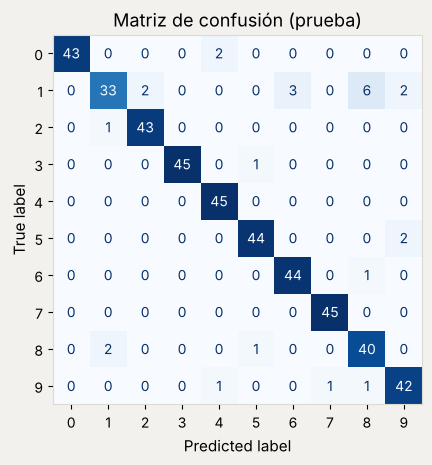

Confusión más frecuente: real 1 -> predicho 8 (6 casos)


In [15]:
pred_te = evaluar(modelo, Xte_t, yte_t)["pred"]
f1m = f1_score(y_te, pred_te, average="macro")
print(f"F1 macro en prueba: {f1m:.3f}")
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=range(10)).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusión (prueba)"); plt.grid(False); plt.show()

# Los pares de dígitos más confundidos
cm = confusion_matrix(y_te, pred_te); np.fill_diagonal(cm, 0)
i, j = np.unravel_index(cm.argmax(), cm.shape)
print(f"Confusión más frecuente: real {i} -> predicho {j} ({cm[i, j]} casos)")

## Parte D — Preguntas de comprensión (5 min)

Con la función `entrenar` ya lista, responde experimentando.

1. **Tasa de aprendizaje.** Entrena 15 épocas con `SGD` y `lr ∈ {1e-4, 0.1, 5}` (misma semilla) y grafica las tres curvas de pérdida de entrenamiento.
2. **Sin ReLU.** Entrena la misma red sin las activaciones (solo `Linear → Linear → Linear`) y compara la exactitud de prueba con la red con ReLU.

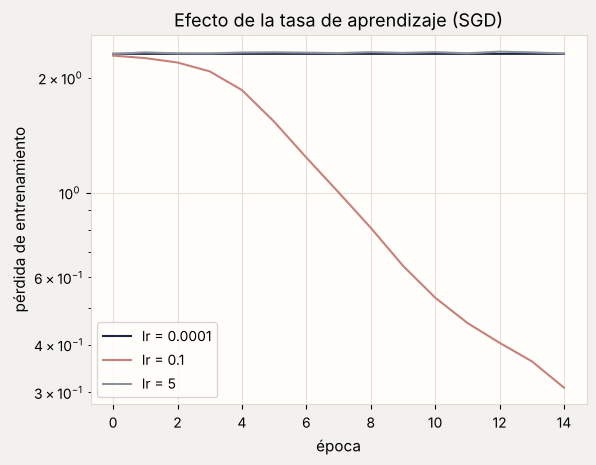

lr = 0.0001: pérdida final 2.3078 | exactitud de prueba 0.131
lr = 0.1: pérdida final 0.3085 | exactitud de prueba 0.893
lr = 5: pérdida final 2.3127 | exactitud de prueba 0.098


In [16]:
curvas_lr = {}
for lr in [1e-4, 0.1, 5.0]:
    torch.manual_seed(SEED)
    m = crear_red_base()
    h = entrenar(m, torch.optim.SGD(m.parameters(), lr=lr), Xtr_t, ytr_t, Xte_t, yte_t, epocas=EPOCAS["lr_corto"])
    curvas_lr[lr] = h

for lr, h in curvas_lr.items():
    plt.plot(h["loss_tr"], label=f"lr = {lr:g}")
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("pérdida de entrenamiento"); plt.title("Efecto de la tasa de aprendizaje (SGD)"); plt.legend(); plt.show()
for lr, h in curvas_lr.items():
    print(f"lr = {lr:g}: pérdida final {h['loss_tr'][-1]:.4f} | exactitud de prueba {h['acc_ev'][-1]:.3f}")

**Pregunta:** ¿Qué pasa con la pérdida si `lr = 5`? ¿Y si `lr = 1e-4`? Relaciónalo con la figura de la Teoría 1 sobre el tamaño del paso.

**Respuesta (modelo):** Con `lr = 1e-4` los pasos son tan pequeños que en 15 épocas la pérdida casi no se mueve (≈ 2,31, que es el valor del azar, ln 10 ≈ 2,30; exactitud de prueba 13 %): el entrenamiento es demasiado lento. Con `lr = 5` los pasos son tan grandes que el descenso se pasa del mínimo: la pérdida no baja y queda también cerca de 2,31 (exactitud 10 %, es decir, azar); en otras redes se vería como oscilaciones o `NaN`. Con `lr = 0,1` baja bien (pérdida 0,31, exactitud 89 % en 15 épocas). Es la figura de la Teoría 1: paso muy chico = lento, paso muy grande = divergencia o saltos alrededor del mínimo.

In [17]:
torch.manual_seed(SEED)
sin_relu = nn.Sequential(nn.Linear(64, 64), nn.Linear(64, 32), nn.Linear(32, 10))
h_lin = entrenar(sin_relu, torch.optim.SGD(sin_relu.parameters(), lr=0.1), Xtr_t, ytr_t, Xte_t, yte_t, epocas=EPOCAS["lab1"])
print(f"Con ReLU:  exactitud de prueba = {hist1['acc_ev'][-1]:.3f}")
print(f"Sin ReLU:  exactitud de prueba = {h_lin['acc_ev'][-1]:.3f}")

# Tres capas lineales apiladas equivalen a UNA sola capa lineal: W = W3 W2 W1
with torch.no_grad():
    L1, L2, L3 = sin_relu[0], sin_relu[1], sin_relu[2]
    W_eq = L3.weight @ L2.weight @ L1.weight
    b_eq = L3.weight @ (L2.weight @ L1.bias + L2.bias) + L3.bias
    una_capa = Xte_t @ W_eq.T + b_eq
    print("¿Salida idéntica a la de una sola capa lineal?", torch.allclose(sin_relu(Xte_t), una_capa, atol=1e-4))

Con ReLU:  exactitud de prueba = 0.942
Sin ReLU:  exactitud de prueba = 0.964
¿Salida idéntica a la de una sola capa lineal? True


**Pregunta:** ¿Qué ocurre si se eliminan las ReLU? Compara las exactitudes y usa la última celda (la equivalencia con una sola capa lineal). ¿Contradice lo que viste con XOR? Explica por qué sí o por qué no.

**Respuesta (modelo):** Sin ReLU la red es una composición de transformaciones lineales y equivale a **una sola** capa lineal $W=W_3W_2W_1$ (la última celda lo comprueba: `True`); no puede representar fronteras no lineales como la de XOR. Sin embargo, en esta ejecución la red sin ReLU obtuvo 96,4 % de exactitud de prueba frente a 94,2 % con ReLU. **No contradice la teoría:** los dígitos de 8×8 son casi separables linealmente (una regresión logística ya rinde ≈ 95-97 %), así que un modelo lineal basta y, con pocos datos y 30 épocas de SGD, el más simple incluso entrena más rápido. La no linealidad es *necesaria* para problemas como XOR y para imágenes más difíciles (CNN, clase 11), pero en este conjunto no se nota. Con una sola ejecución y 450 ejemplos de prueba, además, una diferencia de ~2 puntos queda dentro del ruido (ver el IC de la Parte D del Lab 2).

---
# LAB 2 — Entrenar bien la red
---
Se continúa en el mismo notebook, con la misma red de los dígitos. Desde aquí se usan **tres conjuntos**, como se vio en la clase 9:

* **entrenamiento** (`X_pool`, 1.047 imágenes), de donde sale también el subconjunto pequeño de la Parte B;
* **validación** (`X_val`, 300 imágenes): sirve para comparar configuraciones y para el *early stopping*;
* **prueba** (`X_te`, 450 imágenes, la misma del Lab 1): **no se toca hasta la Parte D**.

In [18]:
X_pool, X_val, y_pool, y_val = train_test_split(X_tr, y_tr, test_size=300, stratify=y_tr, random_state=SEED)
Xp_t, yp_t = a_tensores(X_pool, y_pool)
Xv_t, yv_t = a_tensores(X_val, y_val)
print("entrenamiento:", Xp_t.shape[0], "| validación:", Xv_t.shape[0], "| prueba (intacta):", Xte_t.shape[0])

entrenamiento: 1047 | validación: 300 | prueba (intacta): 450


## Parte A — Optimizadores en comparación (20 min)

Entrena la red base 30 épocas con la **misma inicialización y el mismo orden de mini-batches** para:

| Optimizador | Hiperparámetros |
|---|---|
| SGD | `lr=0.1` |
| SGD + momentum | `lr=0.1`, `momentum=0.9` |
| RMSprop | `lr=1e-3` |
| Adam | `lr=1e-3` |

Grafica las cuatro curvas de pérdida de entrenamiento en un solo gráfico y tabula la exactitud en **validación**. Luego prueba **Adam** con `lr ∈ {1e-4, 1e-3, 1e-2, 1e-1}`.

In [19]:
optimizadores = {
    "SGD (lr=0.1)": lambda params: torch.optim.SGD(params, lr=0.1),
    "SGD + momentum (lr=0.1, β=0.9)": lambda params: torch.optim.SGD(params, lr=0.1, momentum=0.9),
    "RMSprop (lr=1e-3)": lambda params: torch.optim.RMSprop(params, lr=1e-3),
    "Adam (lr=1e-3)": lambda params: torch.optim.Adam(params, lr=1e-3),
}

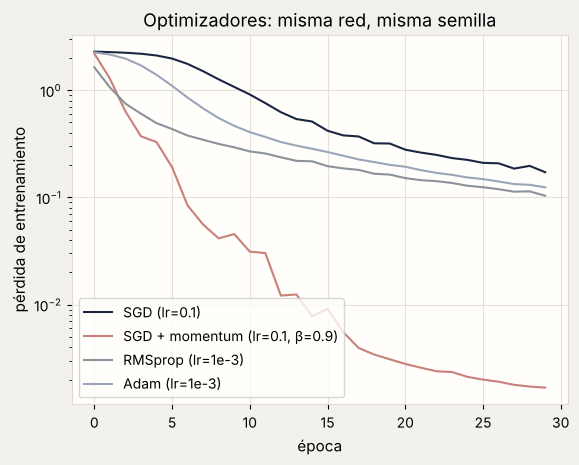

,pérdida entr. final,exactitud val. final,mejor exactitud val.
SGD (lr=0.1),0.1718,0.9400,0.9600
"SGD + momentum (lr=0.1, β=0.9)",0.0017,0.9767,0.9833
RMSprop (lr=1e-3),0.1037,0.9667,0.9667
Adam (lr=1e-3),0.1242,0.9567,0.9667


In [20]:
hist_opt = {}
for nombre, fabrica in optimizadores.items():
    torch.manual_seed(SEED)                      # misma inicialización para todos
    m = crear_red_base()
    hist_opt[nombre] = entrenar(m, fabrica(m.parameters()), Xp_t, yp_t, Xv_t, yv_t, epocas=EPOCAS["opt"])

for nombre, h in hist_opt.items():
    plt.plot(h["loss_tr"], label=nombre)
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("pérdida de entrenamiento"); plt.title("Optimizadores: misma red, misma semilla"); plt.legend(); plt.show()

tabla_opt = pd.DataFrame({n: {"pérdida entr. final": h["loss_tr"][-1], "exactitud val. final": h["acc_ev"][-1],
                             "mejor exactitud val.": max(h["acc_ev"])} for n, h in hist_opt.items()}).T
tabla_opt.round(4)

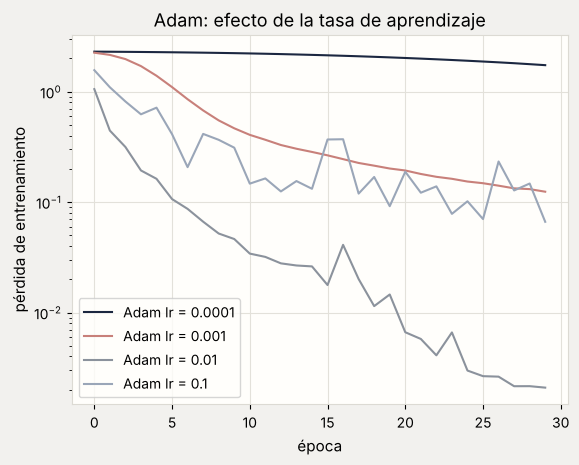

           pérdida entr. final  exactitud val. final
lr=0.0001               1.7372                0.6267
lr=0.001                0.1242                0.9567
lr=0.01                 0.0021                0.9667
lr=0.1                  0.0663                0.9267


In [21]:
lrs_adam = [1e-4, 1e-3, 1e-2, 1e-1]
hist_adam = {}
for lr in lrs_adam:
    torch.manual_seed(SEED)
    m = crear_red_base()
    hist_adam[lr] = entrenar(m, torch.optim.Adam(m.parameters(), lr=lr), Xp_t, yp_t, Xv_t, yv_t, epocas=EPOCAS["opt"])

for lr, h in hist_adam.items():
    plt.plot(h["loss_tr"], label=f"Adam lr = {lr:g}")
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("pérdida de entrenamiento"); plt.title("Adam: efecto de la tasa de aprendizaje"); plt.legend(); plt.show()
print(pd.DataFrame({f"lr={lr:g}": {"pérdida entr. final": h["loss_tr"][-1], "exactitud val. final": h["acc_ev"][-1]} for lr, h in hist_adam.items()}).T.round(4))

**Pregunta:** Compara las cuatro curvas: ¿qué optimizador baja más rápido la pérdida de entrenamiento y cuál obtiene mejor exactitud en validación? ¿Son lo mismo? ¿Qué pasa con Adam y `lr=1e-1`?

**Respuesta (modelo):** En esta ejecución, **SGD + momentum** baja más rápido la pérdida de entrenamiento (0,0017 al final) y también obtiene la mejor exactitud de validación (97,7 %); le siguen RMSprop (96,7 %), Adam (95,7 %) y SGD simple (94,0 %). La pérdida de entrenamiento baja y la exactitud de validación no son lo mismo: una pérdida de entrenamiento casi nula puede indicar que se está memorizando. Sobre Adam: `lr = 1e-4` es demasiado lento (pérdida 1,74, 62,7 %), `1e-3` y `1e-2` funcionan (95,7 % y 96,7 %; con 1e-2 la pérdida de entrenamiento es 0,002) y `lr = 1e-1` es demasiado alto: pasos inestables y el peor resultado entre los que aprenden (92,7 %). Adam adapta el paso por parámetro, pero **no elimina** la necesidad de elegir bien `lr`. Además, SGD+momentum con `lr=0,1` resultó mejor que Adam en este problema pequeño: no siempre gana Adam. (Diferencias de 1 punto sobre 300 ejemplos de validación son ruido: no sacar conclusiones fuertes con una sola semilla.)

## Parte B — Provocar sobreajuste (10 min)

Para ver el sobreajuste hay que dejarlo ocurrir: se usan **solo 200 imágenes de entrenamiento** y una red **más ancha** (`64 → 256 → 128 → 10`, sin regularización), entrenada hasta 200 épocas con Adam (`lr=1e-3`, mini-batches de 32).

Primero se escribe `crear_mlp`, una fábrica de redes que será la base de los remedios de la Parte C:

```python
crear_mlp(capas, dropout=0.0, batchnorm=False)
```

* `capas`: lista de tamaños, p. ej. `[64, 256, 128, 10]`;
* tras cada capa lineal **oculta**: (opcional) `BatchNorm1d` → `ReLU` → (opcional) `Dropout(dropout)`;
* la última capa lineal no lleva activación.

In [22]:
def crear_mlp(capas, dropout=0.0, batchnorm=False):
    """MLP con ReLU. Orden en cada capa oculta: Linear -> (BatchNorm1d) -> ReLU -> (Dropout)."""
    mods = []
    for i in range(len(capas) - 2):
        mods.append(nn.Linear(capas[i], capas[i + 1]))
        if batchnorm:
            mods.append(nn.BatchNorm1d(capas[i + 1]))
        mods.append(nn.ReLU())
        if dropout > 0:
            mods.append(nn.Dropout(dropout))
    mods.append(nn.Linear(capas[-2], capas[-1]))
    return nn.Sequential(*mods)

In [23]:
# Autocomprobación de crear_mlp
base = crear_mlp([64, 64, 32, 10])
assert sum(p.numel() for p in base.parameters()) == 6570, "Sin BatchNorm ni Dropout debe coincidir con la red base (6570 parámetros)"
assert any(isinstance(m, nn.Dropout) for m in crear_mlp([64, 64, 32, 10], dropout=0.3)), "Falta Dropout"
con_bn = crear_mlp([64, 64, 32, 10], batchnorm=True)
assert any(isinstance(m, nn.BatchNorm1d) for m in con_bn), "Falta BatchNorm1d"
assert sum(p.numel() for p in con_bn.parameters()) == 6570 + 2 * (64 + 32), "BatchNorm1d agrega γ y β por neurona oculta"
assert not isinstance(crear_mlp([64, 64, 32, 10], dropout=0.3, batchnorm=True)[-1], (nn.ReLU, nn.Dropout)), "La última capa debe ser lineal"
print("crear_mlp correcta.")

crear_mlp correcta.


Entrenamiento pequeño: 200 imágenes | clases: [20 20 20 20 20 20 20 20 20 20]


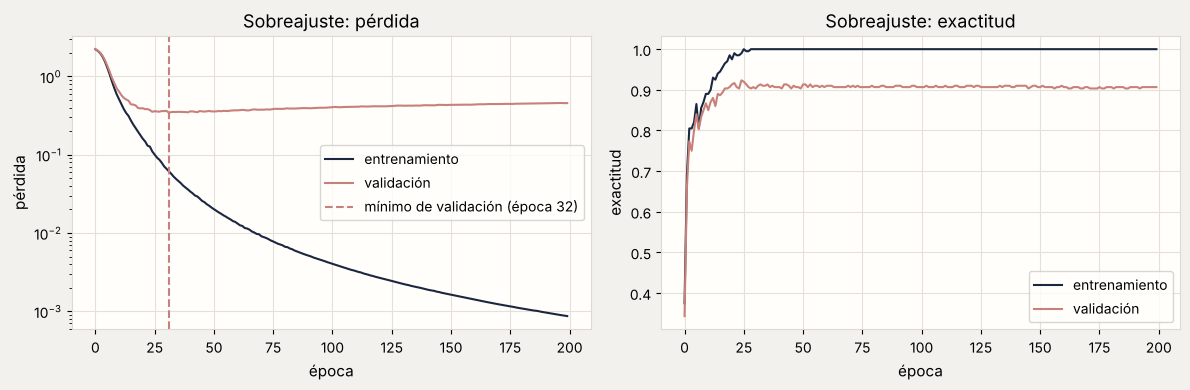

Mínimo de la pérdida de validación en la época 32: 0.343
Al final: pérdida de validación 0.456 | exactitud entr. 1.000 | exactitud val. 0.907


In [24]:
X_peq, _, y_peq, _ = train_test_split(X_pool, y_pool, train_size=200, stratify=y_pool, random_state=SEED)
Xs_t, ys_t = a_tensores(X_peq, y_peq)
print("Entrenamiento pequeño:", Xs_t.shape[0], "imágenes | clases:", np.bincount(y_peq))

torch.manual_seed(SEED)
m_sobre = crear_mlp([64, 256, 128, 10])
hist_sobre = entrenar(m_sobre, torch.optim.Adam(m_sobre.parameters(), lr=1e-3), Xs_t, ys_t, Xv_t, yv_t,
                      epocas=EPOCAS["sobreajuste"], batch_size=32)
ep_min = int(np.argmin(hist_sobre["loss_ev"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_sobre["loss_tr"], label="entrenamiento"); ax[0].plot(hist_sobre["loss_ev"], label="validación")
ax[0].axvline(ep_min, color=ROSA, ls="--", label=f"mínimo de validación (época {ep_min + 1})")
ax[0].set_yscale("log"); ax[0].set_xlabel("época"); ax[0].set_ylabel("pérdida"); ax[0].set_title("Sobreajuste: pérdida"); ax[0].legend()
ax[1].plot(hist_sobre["acc_tr"], label="entrenamiento"); ax[1].plot(hist_sobre["acc_ev"], label="validación")
ax[1].set_xlabel("época"); ax[1].set_ylabel("exactitud"); ax[1].set_title("Sobreajuste: exactitud"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Mínimo de la pérdida de validación en la época {ep_min + 1}: {hist_sobre['loss_ev'][ep_min]:.3f}")
print(f"Al final: pérdida de validación {hist_sobre['loss_ev'][-1]:.3f} | exactitud entr. {hist_sobre['acc_tr'][-1]:.3f} | exactitud val. {hist_sobre['acc_ev'][-1]:.3f}")

**Pregunta:** ¿En qué época empieza a empeorar la pérdida de validación y qué sigue haciendo la pérdida de entrenamiento? ¿Se nota igual en la exactitud? Explica la diferencia.

**Respuesta (modelo):** La pérdida de validación alcanza su mínimo en la época 32 (0,343) y desde ahí **sube** (0,456 al final), mientras la pérdida de entrenamiento sigue bajando hasta casi 0: la red empieza a memorizar los 200 ejemplos. La exactitud, en cambio, apenas se resiente (entrenamiento 100 %, validación ≈ 90,7 %): la pérdida penaliza la *confianza* en las predicciones erradas (probabilidades extremas), mientras que la exactitud solo cuenta aciertos y desaciertos, así que la red puede seguir acertando igual y aun así estar peor calibrada. Por eso conviene mirar la curva de pérdida de validación y no solo la exactitud.

## Parte C — Remedios, uno por uno (25 min)

Partiendo de la Parte B (mismos 200 ejemplos, misma red ancha), se prueba **una intervención a la vez** y luego la combinación:

| Configuración | Qué se cambia |
|---|---|
| base | nada (la Parte B) |
| L2 | `weight_decay=1e-3` en Adam |
| Dropout | `Dropout(0.3)` entre capas |
| BatchNorm | `BatchNorm1d` después de las lineales |
| Early stopping | detener con paciencia 10 y quedarse con los **mejores pesos** |
| Combinación | Dropout + L2 + early stopping |

Primero, `entrenar_early_stopping`: entrena hasta `epocas_max`, evalúa la **pérdida de validación** al final de cada época y, si no mejora durante `paciencia` épocas seguidas, se detiene y **restaura** los pesos de la mejor época.

In [25]:
def entrenar_early_stopping(modelo, optimizador, X_tr, y_tr, X_ev, y_ev, epocas_max=200, paciencia=10, batch_size=32, seed=SEED):
    """Early stopping sobre la pérdida de validación. Restaura los mejores pesos.
    Devuelve (historial, mejor_epoca) con mejor_epoca contada desde 1."""
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True, generator=g, drop_last=True)
    criterio = nn.CrossEntropyLoss()
    hist = {"loss_tr": [], "acc_tr": [], "loss_ev": [], "acc_ev": []}
    mejor_loss, mejor_epoca, mejores_pesos, sin_mejora = float("inf"), 0, None, 0
    for ep in range(1, epocas_max + 1):
        entrenar_una_epoca(modelo, optimizador, loader, criterio)
        r_tr, r_ev = evaluar(modelo, X_tr, y_tr), evaluar(modelo, X_ev, y_ev)
        hist["loss_tr"].append(r_tr["loss"]); hist["acc_tr"].append(r_tr["acc"])
        hist["loss_ev"].append(r_ev["loss"]); hist["acc_ev"].append(r_ev["acc"])
        if r_ev["loss"] < mejor_loss:
            mejor_loss, mejor_epoca, sin_mejora = r_ev["loss"], ep, 0
            mejores_pesos = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejores_pesos)
    return hist, mejor_epoca

In [26]:
# Autocomprobación del early stopping
torch.manual_seed(SEED)
_m = crear_mlp([64, 256, 128, 10])
_h, _ep = entrenar_early_stopping(_m, torch.optim.Adam(_m.parameters(), lr=1e-3), Xs_t, ys_t, Xv_t, yv_t, epocas_max=EPOCAS["sobreajuste"])
assert len(_h["loss_ev"]) < EPOCAS["sobreajuste"], "El early stopping debería detener antes de las épocas máximas en este problema"
assert abs(evaluar(_m, Xv_t, yv_t)["loss"] - min(_h["loss_ev"])) < 1e-5, "Tras el entrenamiento el modelo debe tener los pesos de la MEJOR época"
print(f"Early stopping: se detuvo en la época {len(_h['loss_ev'])}; mejores pesos de la época {_ep}.")

Early stopping: se detuvo en la época 42; mejores pesos de la época 32.


In [27]:
# Definición de configuraciones (cada una es un diccionario de opciones)
CONFIGS = {
    "base":           dict(dropout=0.0, batchnorm=False, wd=0.0,  es=False),
    "L2":             dict(dropout=0.0, batchnorm=False, wd=1e-3, es=False),
    "Dropout":        dict(dropout=0.3, batchnorm=False, wd=0.0,  es=False),
    "BatchNorm":      dict(dropout=0.0, batchnorm=True,  wd=0.0,  es=False),
    "Early stopping": dict(dropout=0.0, batchnorm=False, wd=0.0,  es=True),
    "Combinación":    dict(dropout=0.3, batchnorm=False, wd=1e-3, es=True),
}

In [28]:
def entrenar_config(cfg, seed=SEED, X_tr=Xs_t, y_tr=ys_t, X_ev=Xv_t, y_ev=yv_t):
    """Crea y entrena la red ancha con la configuración `cfg`. Devuelve (modelo, historial, epoca_final)."""
    torch.manual_seed(seed)
    m = crear_mlp([64, 256, 128, 10], dropout=cfg["dropout"], batchnorm=cfg["batchnorm"])
    opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=cfg["wd"])
    if cfg["es"]:
        hist, ep = entrenar_early_stopping(m, opt, X_tr, y_tr, X_ev, y_ev, epocas_max=EPOCAS["sobreajuste"], paciencia=10, seed=seed)
    else:
        hist = entrenar(m, opt, X_tr, y_tr, X_ev, y_ev, epocas=EPOCAS["sobreajuste"], batch_size=32, seed=seed)
        ep = len(hist["loss_ev"])
    return m, hist, ep


resultados, modelos_cfg, hist_cfg = {}, {}, {}
for nombre, cfg in CONFIGS.items():
    m, h, ep = entrenar_config(cfg)
    r_tr, r_va = evaluar(m, Xs_t, ys_t), evaluar(m, Xv_t, yv_t)
    resultados[nombre] = {"época del modelo final": ep, "exactitud entr.": r_tr["acc"], "exactitud val.": r_va["acc"],
                          "F1 macro val.": f1_score(y_val, r_va["pred"], average="macro"),
                          "brecha entr.-val.": r_tr["acc"] - r_va["acc"], "pérdida val.": r_va["loss"]}
    modelos_cfg[nombre], hist_cfg[nombre] = m, h

tabla = pd.DataFrame(resultados).T
tabla.round(3)

,época del modelo final,exactitud entr.,exactitud val.,F1 macro val.,brecha entr.-val.,pérdida val.
base,200.0,1.000,0.907,0.907,0.093,0.456
L2,200.0,1.000,0.903,0.903,0.097,0.309
Dropout,200.0,1.000,0.917,0.917,0.083,0.365
BatchNorm,200.0,1.000,0.950,0.950,0.050,0.147
Early stopping,32.0,1.000,0.910,0.910,0.090,0.343
Combinación,57.0,0.995,0.917,0.917,0.078,0.276


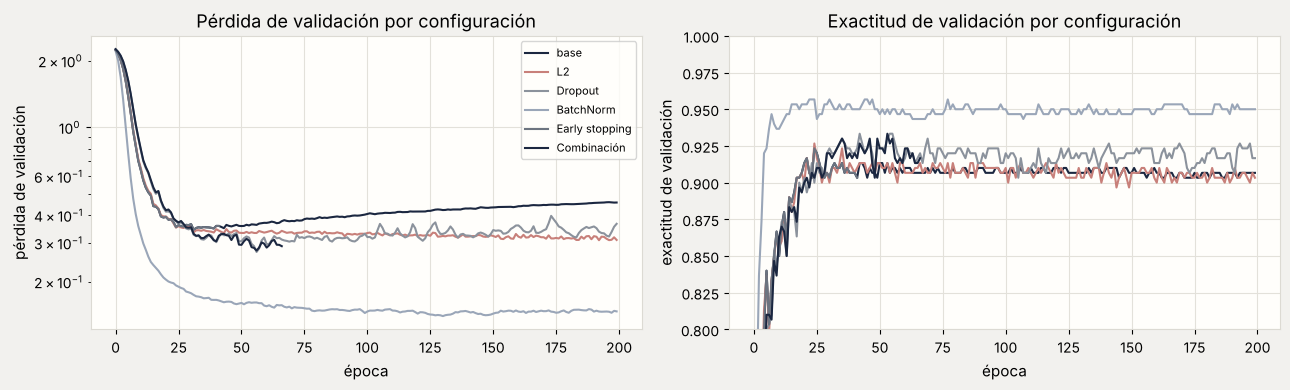

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nombre, h in hist_cfg.items():
    ax[0].plot(h["loss_ev"], label=nombre)
    ax[1].plot(h["acc_ev"], label=nombre)
ax[0].set_yscale("log"); ax[0].set_xlabel("época"); ax[0].set_ylabel("pérdida de validación"); ax[0].set_title("Pérdida de validación por configuración"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("época"); ax[1].set_ylabel("exactitud de validación"); ax[1].set_title("Exactitud de validación por configuración"); ax[1].set_ylim(0.8, 1.0)
plt.tight_layout(); plt.show()

**Opcional — L1 manual.** Suma $\lambda\sum|w|$ a la pérdida (con $\lambda = 10^{-3}$) y cuenta cuántos pesos quedan cerca de cero (|w| < 1e-3) frente a la red base. Recuerda: L1 promueve **dispersión**.

In [30]:
def entrenar_l1(lam=1e-3, epocas=None, seed=SEED):
    epocas = epocas or (100 if not RAPIDO else 30)
    torch.manual_seed(seed)
    m = crear_mlp([64, 256, 128, 10])
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(Xs_t, ys_t), batch_size=32, shuffle=True, generator=g, drop_last=True)
    for _ in range(epocas):
        m.train()
        for xb, yb in loader:
            opt.zero_grad()
            perd = nn.functional.cross_entropy(m(xb), yb) + lam * sum(p.abs().sum() for n_, p in m.named_parameters() if "weight" in n_)
            perd.backward(); opt.step()
    return m


def frac_ceros(m, umbral=1e-3):
    w = torch.cat([p.detach().abs().flatten() for n_, p in m.named_parameters() if "weight" in n_])
    return (w < umbral).float().mean().item()


m_l1 = entrenar_l1()
print(f"Pesos |w| < 1e-3 — base: {frac_ceros(modelos_cfg['base']):.1%} | L1 (λ=1e-3): {frac_ceros(m_l1):.1%} | L2: {frac_ceros(modelos_cfg['L2']):.1%}")
print(f"Exactitud de validación con L1: {evaluar(m_l1, Xv_t, yv_t)['acc']:.3f}")

Pesos |w| < 1e-3 — base: 0.9% | L1 (λ=1e-3): 86.6% | L2: 21.2%
Exactitud de validación con L1: 0.900


**Pregunta:** Según la tabla, ¿qué intervención redujo más la brecha entrenamiento–validación y cuál mejoró más la exactitud de validación? ¿Ayuda la combinación? Explica por qué cada técnica actúa como actúa (L2, Dropout, BatchNorm, early stopping).

**Respuesta (modelo):** Con una semilla y esta configuración: la **brecha entrenamiento–validación** baja más con **BatchNorm** (0,050 frente a 0,093 de la base) y esa misma configuración es la que más mejora la exactitud de validación (95,0 % frente a 90,7 %) y la pérdida de validación (0,147 frente a 0,456). Dropout reduce algo la brecha (0,083; 91,7 %), la combinación Dropout+L2+early stopping también (0,078; 91,7 %), mientras que L2 con `weight_decay=1e-3` casi no cambia la exactitud (90,3 %; solo baja la pérdida de validación a 0,309) y el early stopping solo elige la época 32 (91,0 %). La combinación **no** superó a BatchNorm sola: combinar no siempre suma. Por qué: L2 penaliza pesos grandes y suaviza la función; Dropout apaga neuronas al azar y obliga a que ninguna sea imprescindible (una especie de ensamble); BatchNorm normaliza las activaciones de cada capa, estabiliza el entrenamiento y tiene un leve efecto regularizador por el ruido de los mini-batches; early stopping detiene el entrenamiento cuando la validación deja de mejorar. Los efectos son de 1 a 5 puntos con una semilla y 300 ejemplos de validación: hay que repetir con más semillas antes de afirmar cuál es mejor (ver Parte D). (Opcional: L1 con λ=1e-3 deja ≈ 87 % de los pesos casi en cero, frente a ≈ 1 % en la base y ≈ 21 % con L2, con 90,0 % de exactitud de validación: L1 promueve dispersión.)

## Parte D — Informe con incertidumbre (10 min)

Se elige la mejor configuración **según la validación** (F1 macro) y recién entonces se mira la **prueba, una sola vez**.

1. Reentrena esa configuración con **3 semillas** (`SEED`, `SEED+1`, `SEED+2`) y reporta media ± desviación estándar de la exactitud de prueba.
2. Para el modelo de la primera semilla, calcula el **intervalo de confianza del 95 % por bootstrap** de la exactitud de prueba (1.000 remuestreos con reemplazo del conjunto de prueba, percentiles 2,5 y 97,5; herramienta de la clase 9).
3. Escribe tres conclusiones.

In [31]:
def ic_bootstrap_exactitud(y_real, y_pred, B=1000, nivel=0.95, seed=SEED):
    """IC percentil por bootstrap de la exactitud. Devuelve ((inferior, superior), distribución_bootstrap)."""
    rng = np.random.default_rng(seed)
    aciertos = (np.asarray(y_real) == np.asarray(y_pred)).astype(float)
    n = len(aciertos)
    medias = np.array([aciertos[rng.integers(0, n, n)].mean() for _ in range(B)])
    alfa = (1 - nivel) / 2
    return tuple(np.quantile(medias, [alfa, 1 - alfa])), medias

In [32]:
# Autocomprobación del bootstrap con un caso conocido: 90 aciertos de 100
(lo, hi), dist = ic_bootstrap_exactitud(np.r_[np.ones(90), np.zeros(10)], np.ones(100))
assert len(dist) == 1000 and 0.82 < lo < 0.90 < hi < 0.97, f"IC inesperado para 90/100: ({lo:.3f}, {hi:.3f})"
print(f"IC95 % de 90/100 aciertos: [{lo:.3f}, {hi:.3f}]  (correcto)")

IC95 % de 90/100 aciertos: [0.840, 0.950]  (correcto)


Mejor configuración según F1 macro de validación: BatchNorm


Exactitud de prueba por semilla: [0.9378 0.9556 0.9533]
Media ± desviación estándar (3 semillas): 0.9489 ± 0.0097
IC95 % bootstrap (semilla 42, n = 450): [0.9155, 0.9578]


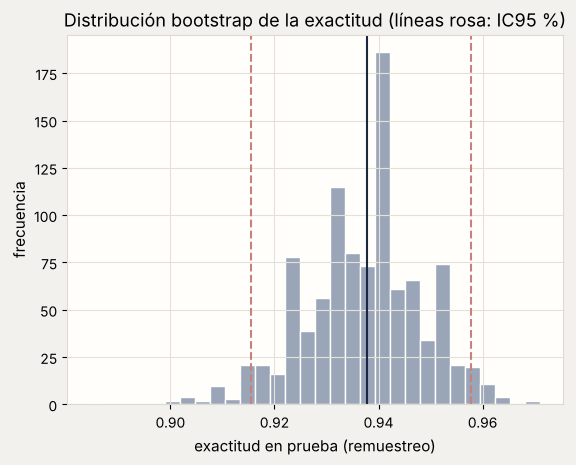

In [33]:
mejor = tabla["F1 macro val."].idxmax()
print("Mejor configuración según F1 macro de validación:", mejor)

exact_test, preds_test = [], []
for k in range(3):
    m, _, _ = entrenar_config(CONFIGS[mejor], seed=SEED + k)
    r = evaluar(m, Xte_t, yte_t)          # <- la prueba se usa UNA vez por modelo final
    exact_test.append(r["acc"]); preds_test.append(r["pred"])

exact_test = np.array(exact_test)
(lo, hi), dist = ic_bootstrap_exactitud(y_te, preds_test[0])
print(f"Exactitud de prueba por semilla: {np.round(exact_test, 4)}")
print(f"Media ± desviación estándar (3 semillas): {exact_test.mean():.4f} ± {exact_test.std(ddof=1):.4f}")
print(f"IC95 % bootstrap (semilla {SEED}, n = {len(y_te)}): [{lo:.4f}, {hi:.4f}]")

plt.hist(dist, bins=30, color="#9aa6b8", edgecolor="white")
plt.axvline(lo, color=ROSA, ls="--"); plt.axvline(hi, color=ROSA, ls="--")
plt.axvline(exact_test[0], color=MARINO); plt.xlabel("exactitud en prueba (remuestreo)"); plt.ylabel("frecuencia")
plt.title("Distribución bootstrap de la exactitud (líneas rosa: IC95 %)"); plt.show()

### Conclusiones

Escribe tres conclusiones (qué optimizador, qué remedio funcionó mejor y por qué):

**Conclusión 1** — Optimizador:

**Respuesta (modelo):** Con estos hiperparámetros, SGD con momentum (lr=0,1, β=0,9) y RMSprop dieron mejor validación que Adam (lr=1e-3), pero las diferencias son de 1 a 2 puntos sobre 300 ejemplos de validación, una sola semilla: están dentro del ruido. Lo robusto es que Adam con `lr` demasiado chico o demasiado grande rinde mucho peor: **elegir bien la tasa de aprendizaje importa más que el nombre del optimizador**. Adam con `lr=1e-3` es un buen punto de partida porque requiere poco ajuste.

**Conclusión 2** — Remedio contra el sobreajuste:

**Respuesta (modelo):** En este problema (200 ejemplos, red ancha) el remedio más eficaz fue BatchNorm (validación 95,0 %, brecha 0,050, frente a 90,7 % y 0,093 de la base). Dropout y la combinación ayudaron algo; L2 débil y early stopping solos casi no cambiaron la exactitud, aunque el early stopping ahorró cómputo (la mejor época fue la 32 de 200). La causa del sobreajuste es tener muy pocos datos para una red con ~49.000 parámetros; la solución más segura sigue siendo conseguir más datos.

**Conclusión 3** — Incertidumbre del resultado final:

**Respuesta (modelo):** El mejor modelo según validación (BatchNorm, por F1 macro) alcanzó en prueba 93,8 %, 95,6 % y 95,3 % con tres semillas: media 94,9 % ± 1,0 puntos (desviación estándar). El IC95 % por bootstrap de la semilla 42 es [91,6 %, 95,8 %] (n=450): el error de muestreo del conjunto de prueba es del orden de ±2 puntos. Conclusión: se puede decir «≈ 95 % ± 2 puntos»; diferencias de 1 punto entre configuraciones no son distinguibles de la variación por semilla ni del muestreo, y la prueba se mira una sola vez, al final, para no sesgar la elección.

---
## Entregable

Un único notebook con el **Lab 1 y el Lab 2 ejecutados**, las respuestas a las preguntas y las **tres conclusiones** de la Parte D del Lab 2. Entrega por AULA-USM.

In [34]:
print(f"Tiempo total de ejecución: {time.time() - T0:.0f} s")

Tiempo total de ejecución: 41 s
